In [28]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import LSTM, Dense, SimpleRNN
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [30]:
data = np.loadtxt("/content/drive/MyDrive/Inverse Kinematics Dataset/robot_inverse_kinematics_dataset.csv", skiprows=1, delimiter=',')
print(data.shape)
print(type(data))

(15000, 9)
<class 'numpy.ndarray'>


In [31]:
# Load data (CSV file)

# data: numpy array, first 6 columns are joint angles, last 3 are xyz
q = data[:, :6] # Joint angles
xyz = data[:, 6:] # End-effector position

scaler = MinMaxScaler()
q_scaled = scaler.fit_transform(q)
xyz_scaled = scaler.fit_transform(xyz)

# Split data into training and validation sets
q_train, q_val, xyz_train, xyz_val = train_test_split(q_scaled, xyz_scaled, test_size=0.2, random_state=42)

# Print shapes of training and validation sets
print('Training set shapes:')
print('q_train:', q_train.shape)
print('xyz_train:', xyz_train.shape)

print('\nValidation set shapes:')
print('q_val:', q_val.shape)
print('xyz_val:', xyz_val.shape)

Training set shapes:
q_train: (12000, 6)
xyz_train: (12000, 3)

Validation set shapes:
q_val: (3000, 6)
xyz_val: (3000, 3)


In [32]:
# Define and train the FNN model
model_fnn = Sequential()
model_fnn.add(Dense(64, input_dim=6, activation='relu'))
model_fnn.add(Dense(32, activation='relu'))
model_fnn.add(Dense(16, activation='relu'))
model_fnn.add(Dense(3))

# Compile the model
model_fnn.compile(loss='mean_squared_error', optimizer='adam')

# Train the model
history_fnn = model_fnn.fit(q_train, xyz_train,
                            epochs=100,
                            batch_size=32,
                            validation_data=(q_val, xyz_val))

# Evaluate the model
loss_fnn = model_fnn.evaluate(q_val, xyz_val, verbose=0)
print(f'FNN validation loss: {loss_fnn:.4f}')

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0561 - val_loss: 0.0245
Epoch 2/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0227 - val_loss: 0.0192
Epoch 3/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0174 - val_loss: 0.0148
Epoch 4/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0133 - val_loss: 0.0107
Epoch 5/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0101 - val_loss: 0.0087
Epoch 6/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0080 - val_loss: 0.0069
Epoch 7/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0065 - val_loss: 0.0060
Epoch 8/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0057 - val_loss: 0.0055
Epoch 9/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0049 - val_loss: 0.0045
Epoch 10/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0044 - val_loss: 0.0041
Epoch 11/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0039 - val_loss: 0.0038
Epoch 12/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

In [33]:
# Make predictions
xyz_pred_scaled = model_fnn.predict(q_val)

# Inverse scale to original units
xyz_pred = scaler.inverse_transform(xyz_pred_scaled)
xyz_true = scaler.inverse_transform(xyz_val)

# Compute metrics
mse = mean_squared_error(xyz_true, xyz_pred)
mae = mean_absolute_error(xyz_true, xyz_pred)
r2 = r2_score(xyz_true, xyz_pred)

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [34]:
# Compute Euclidean distance between predicted xyz and true xyz
ee_error = np.linalg.norm(xyz_true - xyz_pred, axis=1)
mean_ee_error = np.mean(ee_error)
max_ee_error = np.max(ee_error)

In [35]:
# Print metrics
print("Validation Metrics:")
print(f"MSE: {mse:.6f}")
print(f"MAE: {mae:.6f}")
print(f"R²: {r2:.6f}")
print(f"End-Effector Error (mean): {mean_ee_error:.6f}")
print(f"End-Effector Error (max): {max_ee_error:.6f}")

Validation Metrics:
MSE: 0.000318
MAE: 0.013849
R²: 0.971564
End-Effector Error (mean): 0.027816
End-Effector Error (max): 0.103012


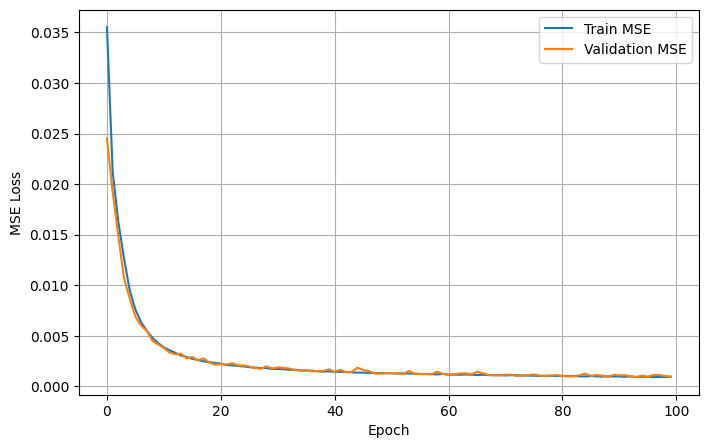

In [36]:
# Plot training & validation loss
plt.figure(figsize=(8, 5))
plt.plot(history_fnn.history['loss'], label='Train MSE')
plt.plot(history_fnn.history['val_loss'], label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
#plt.title('Training vs Validation MSE Loss')
plt.legend()
plt.grid(True)
plt.show()